# Phase 4 · Review training preprocessing and augmentation

Use the local Python 3.13 (`.venv313`) kernel after reviewing and freezing the split. Restart the kernel and run all cells in order from the repository root or the `notebooks` directory so the preview loads the current preprocessing code. The inputs are `configs/data.json`, the verified frozen manifest, and the original images for the selected training IDs. Review the grids before approving a candidate contract.

The deterministic path converts the oriented source to RGB and fits it to the target canvas while preserving proportions. Resizing a 300 × 200 image to a square leaves padding above and below it. The resulting tensor has shape `[height, width, 3]`, with each channel scaled once to float32 in `[0, 1]`. Batching adds a leading axis. TP-09 covers these properties and local/Colab parity. TP-11 covers reproducibility and the training-only augmentation boundary.

In [1]:
from pathlib import Path
import sys

from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
config_path = Path("configs/data.json")
if not (root / config_path).is_file():
    raise FileNotFoundError("Start the notebook in the repository root or notebooks directory.")
sys.path.insert(0, str(root / "src"))

from rps.dataset import filesystem_path
from rps.preview import run_preview

In [2]:
summary = run_preview(root, config_path)
directory = root / "artifacts" / "data" / "phase4" / summary["split_version"]
print("Preview seed", summary["seed"])
print("Class mapping", summary["contract"]["class_mapping"])
for example in summary["examples"]:
    print(example["image_id"], example["label"], example["output_shape"],
          example["output_dtype"], example["output_range"])

Training previews: C:\Users\Niyati\OneDrive\Desktop\rock-paper-scissors-cnn\artifacts\data\phase4\b5fc922ce16bb57bf33a90859a18e8d17cc37b4f294955b4b63ca4d96a50cacb
Candidate contract SHA-256 for approve-contract: d8a84720ee9d18bef96fafee413d0b2918270d006a5c23ee239c1e0aa74b11fa
Preview seed 42
Class mapping {'rock': 0, 'paper': 1, 'scissors': 2}
a780ef14583ea4851f827adba5e923b7d32ec55bcdf36644d3cf5270ac73159a rock [96, 144, 3] float32 [0.0, 0.9450980424880981]
1743027080a6f026fb3e03aa065eb950ef98bdc74f473ae95189066aa99b3603 rock [96, 144, 3] float32 [0.007843137718737125, 0.9686274528503418]
04b6a96e732f2bc785ad7af59e3597263102c97aea238073571e9427d4803259 paper [96, 144, 3] float32 [0.019607843831181526, 0.8823529481887817]
c2193a9ca55c958e53451c7807d3001cf5df865c81bd374105d61105321efeee paper [96, 144, 3] float32 [0.03921568766236305, 0.800000011920929]
89a2a2cd133257e52fc3e8a3e85deab390934b4c080596f5ae05fb9a1c55e118 scissors [96, 144, 3] float32 [0.0, 0.8666666746139526]
7d427e6d03d024

## Compare the sizes

Each row follows one training image from the source through the candidate size and a 128 × 128 comparison. The display scales each panel to fit. Inspect finger separation, thumb position, hand proportions, and padding around the wrist and fingertips. Which size preserves the smallest visible gap between fingers? Record the image ID and explain your choice.

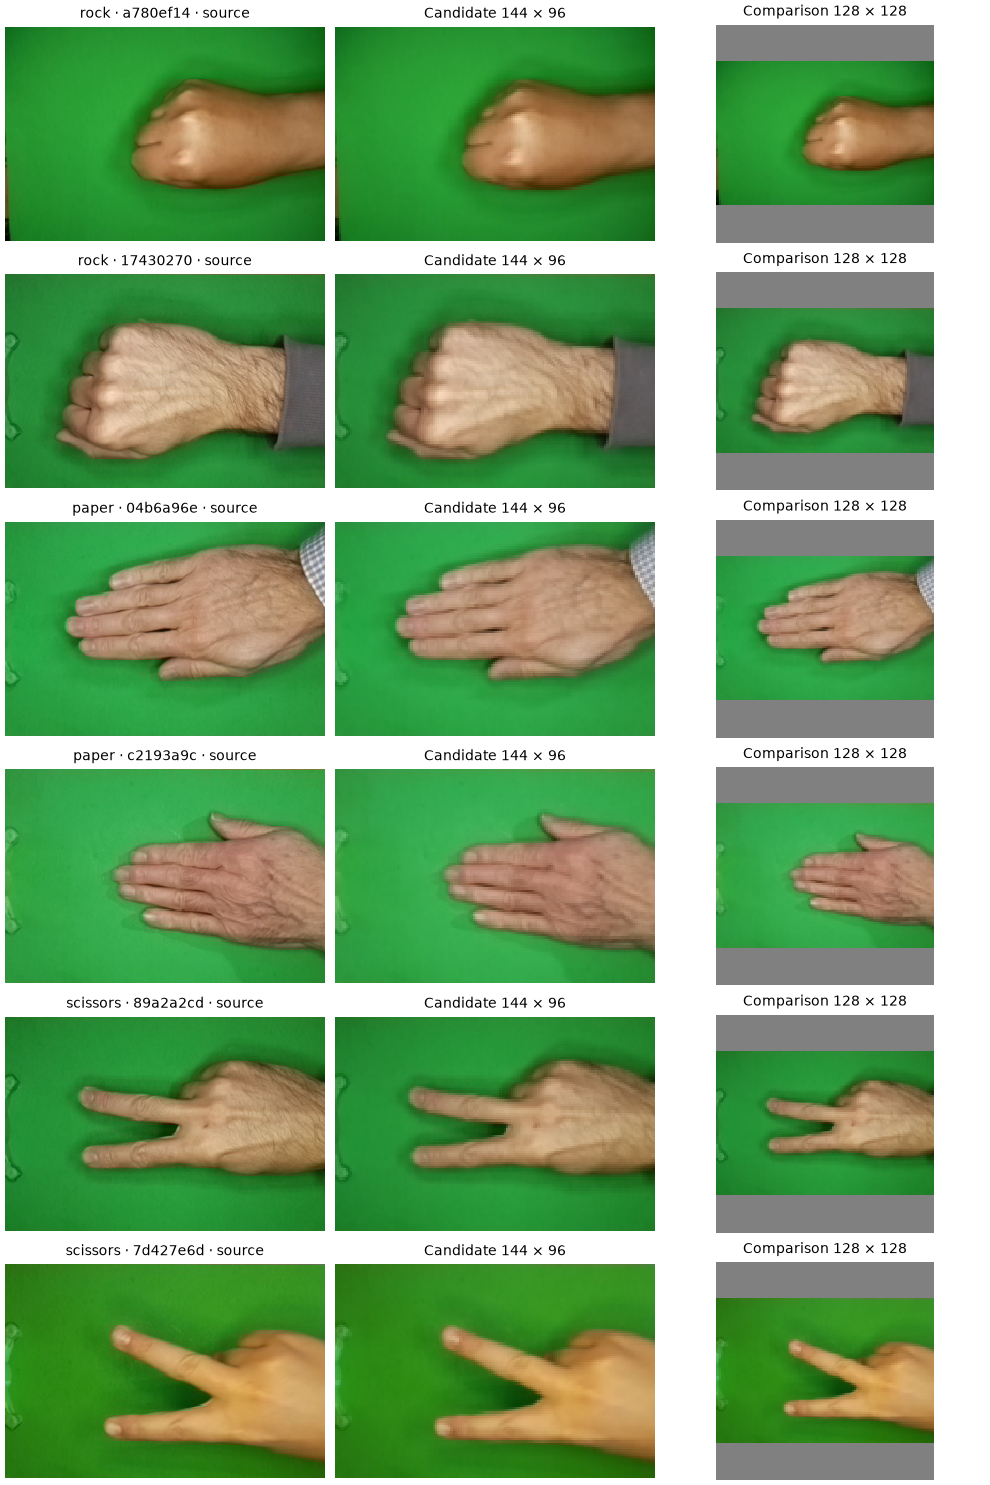

In [3]:
def show_grid(prefix):
    filename = next(name for name in summary["preview_files"] if name.startswith(prefix))
    display(Image(data=filesystem_path(directory / filename).read_bytes(), format="png"))

show_grid("preprocessing-")

## Inspect one change at a time

The first column uses deterministic preprocessing. Each subsequent column applies one seeded transformation to that same tensor. Rotation, translation, and zoom may push fingers outside the frame or create new border cues. Brightness may obscure finger boundaries. The flip trial shows a mirror image even when flipping is disabled in the candidate. Decide whether handedness or framing changes the gesture interpretation.

For each class, record an image ID and whether each proposed range preserves its label. Look closely at wide paper gestures and narrow gaps in scissors examples. Record any setting that needs another preview. The unaugmented baseline uses the deterministic column.

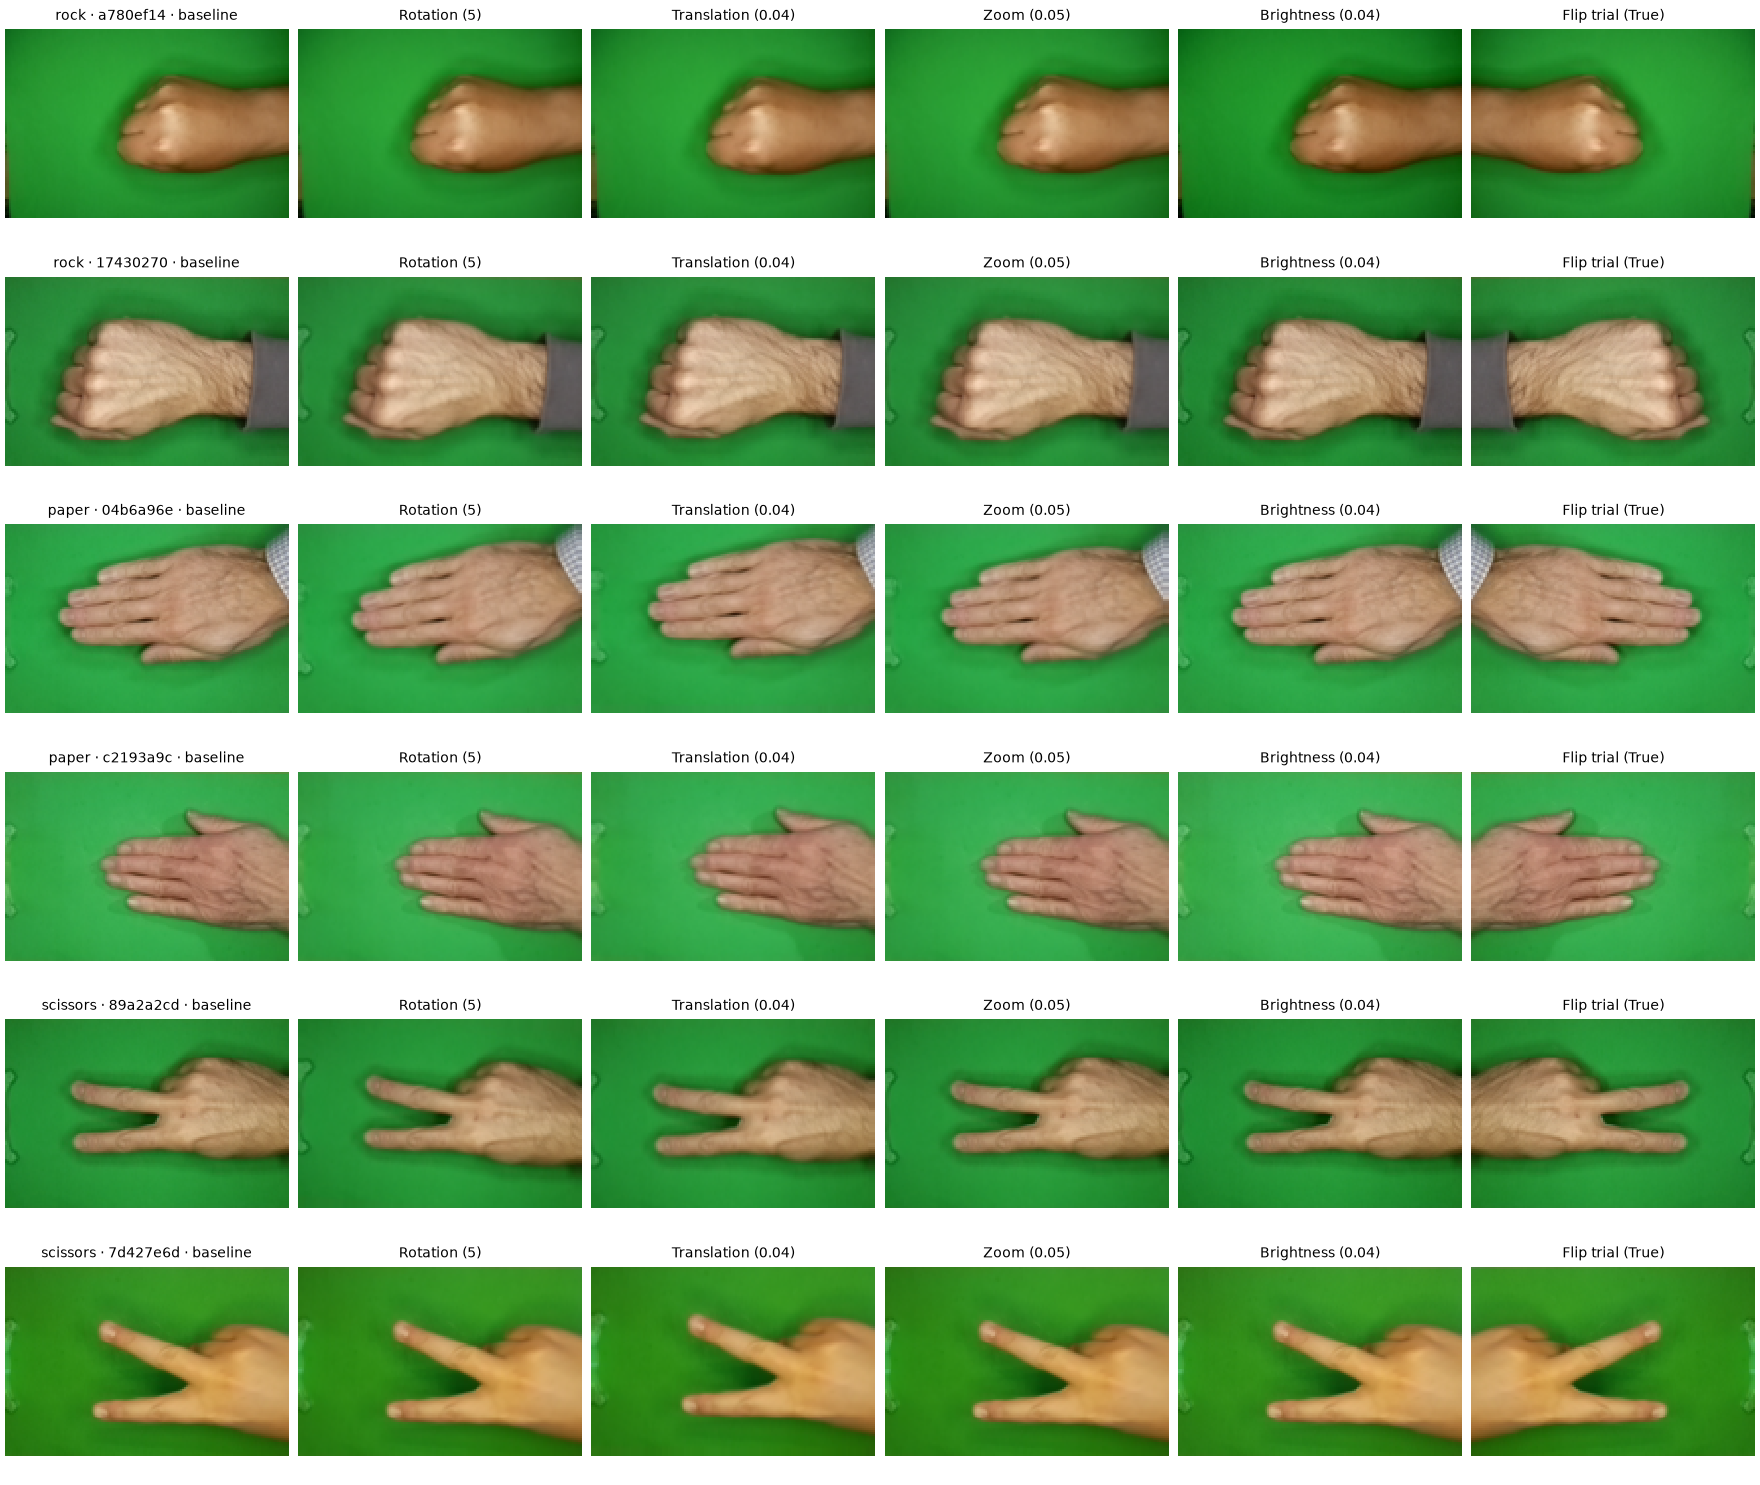

Configured candidate ranges {'rotation_degrees': 5, 'translation_fraction': 0.04, 'zoom_fraction': 0.05, 'brightness_delta': 0.04, 'horizontal_flip': False}
preprocessing-aedcd96b34a38cbe468e481131d8facb5c2623ac84b7e39305d91f8f4d64f1ca.png aedcd96b34a38cbe468e481131d8facb5c2623ac84b7e39305d91f8f4d64f1ca
augmentation-827d4e9d526c7218f245b293d8e47cb016d2bc02745ee6334da89f8a44364746.png 827d4e9d526c7218f245b293d8e47cb016d2bc02745ee6334da89f8a44364746
Review record C:\Users\Niyati\OneDrive\Desktop\rock-paper-scissors-cnn\artifacts\data\phase4\b5fc922ce16bb57bf33a90859a18e8d17cc37b4f294955b4b63ca4d96a50cacb\preview-summary.json


In [4]:
show_grid("augmentation-")
print("Configured candidate ranges", summary["contract"]["augmentation"])
for filename, digest in summary["preview_files"].items():
    print(filename, digest)
print("Review record", directory / "preview-summary.json")

## Record the review

Save the printed digests before repeating the notebook with the same frozen split, configuration, seed, and local runtime. Compare sample IDs, transform seeds in `preview-summary.json`, and both PNG digests. Record any mismatch for TP-11. The review record stores the complete candidate contract and its SHA-256 digest for the approval step.

In the Phase 4 evidence, record the size and padding decision, any gesture or clipping concerns, and the transformation ranges you accept or want revised. To review a revision, update the candidate configuration and run these cells again. Approval requires the owner's decision on the reviewed digest.